In [1]:
import warnings

warnings.filterwarnings('ignore')

import numpy as np

from fulltilt.util import inference

In [2]:
# load model
device = 'cuda'
model, processor_3d, _ = inference.init_model(
    config_file='configs/cfg_cryo.py',
    checkpoint_path='weights/fulltilt.pth',
    device=device,
)

In [3]:
# load tilt-series
tiltseries = np.load('data/test_tiltseries.npy')
ts_min, ts_max = tiltseries.min(), tiltseries.max()
tiltseries = (tiltseries - ts_min) / (ts_max - ts_min) * 255
channels = len(tiltseries)

thetas = [channel_idx * 3 - 60 for channel_idx in range(channels)]

# prepare prompts
prompts_xyz = np.array(
    [
        [121., 70., 128.],
        [281., 62., 130.],
        [47., 341., 130.],
        [278., 294., 116.],
    ],
)

diameter = 10
prompt_num = len(prompts_xyz)
prompts_label = [1] * prompt_num
diameters = np.array([diameter] * prompt_num)

# load tomogram (for plot & proj size)
tomogram = np.load('data/test_tomogram.npy')
nz, ny, nx = tomogram.shape
tomogram_whd=(nx, ny, nz)

In [4]:
prototypes_dict = inference.pipeline_get_prototypes(
    model=model,
    tomogram_whd=tomogram_whd,
    tiltseries=tiltseries,
    thetas=thetas,
    prompts_xyz=prompts_xyz,
    prompts_label=prompts_label,
    diameters=diameters,
    device=device,
)

In [5]:
# load another tilt-series and tomogram
tiltseries = np.load('data/test_tiltseries_cross.npy')
ts_min, ts_max = tiltseries.min(), tiltseries.max()
tiltseries = (tiltseries - ts_min) / (ts_max - ts_min) * 255

tomogram = np.load('data/test_tomogram_cross.npy')
nz, ny, nx = tomogram.shape
tomogram_whd=(nx, ny, nz)

In [6]:
# infer with prototypes
estimated_centers, estimated_diameters, estimated_labels, scores = inference.pipeline_inference_with_prototypes(
    model=model,
    processor_3d=processor_3d,
    tomogram_whd=tomogram_whd,  # reuse; set a different one if applicable
    tiltseries=tiltseries,
    thetas=thetas,  # reuse; set a different one if applicable
    prototypes_dict=prototypes_dict,
    device=device,
)

## Visualization

In [7]:
import matplotlib.pyplot as plt

### On tomogram slices

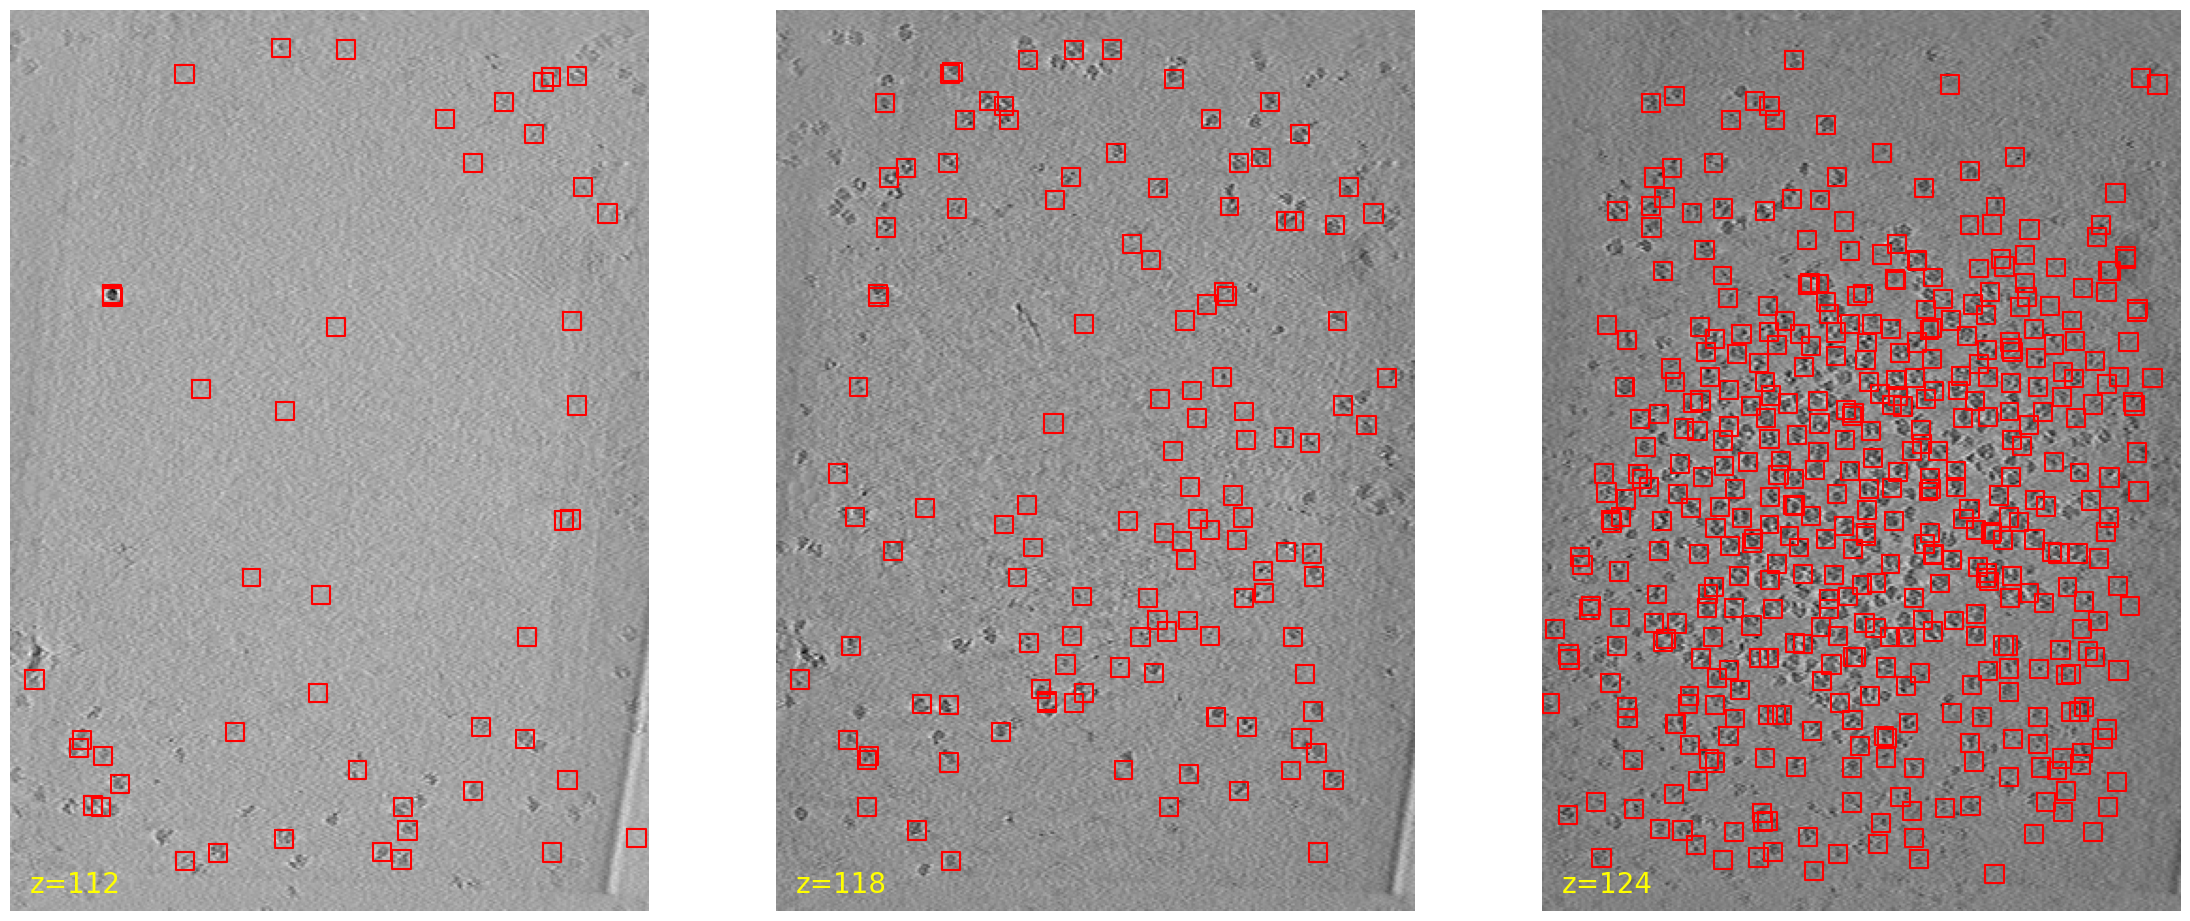

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(28, 12))
for ax_idx, tomogram_channel in enumerate([112, 118, 124]):
    lower_bound = estimated_centers[:, 2] >= tomogram_channel - diameter / 2
    upper_bound = estimated_centers[:, 2] < tomogram_channel + diameter / 2
    estimated_centers_inrange = estimated_centers[np.logical_and(lower_bound, upper_bound)]
    estimated_diameters_inrange = estimated_diameters[np.logical_and(lower_bound, upper_bound)]

    tomogram_slice = tomogram[256 - tomogram_channel].astype(float)
    tomogram_slice = (tomogram_slice - tomogram_slice.min()) / (tomogram_slice.max() - tomogram_slice.min())
    axs[ax_idx].imshow(tomogram_slice, cmap='gray')

    h, w = tomogram_slice.shape
    for est_point, est_diameter in zip(estimated_centers_inrange, estimated_diameters_inrange):
        x, y, z = est_point
        radius = est_diameter / 2
        xs = np.array([x - radius, x - radius, x + radius, x + radius, x - radius])
        ys = np.array([y - radius, y + radius, y + radius, y - radius, y - radius])
        xs[xs < 0] = 0
        ys[ys < 0] = 0
        xs[xs >= w] = w - 1
        ys[ys >= h] = h - 1
        axs[ax_idx].plot(xs, ys, color='red')
    axs[ax_idx].text(10, ny - 10, f'z={tomogram_channel}', color='yellow', size=20)
    axs[ax_idx].axis('off')
plt.show()

### On tilt images

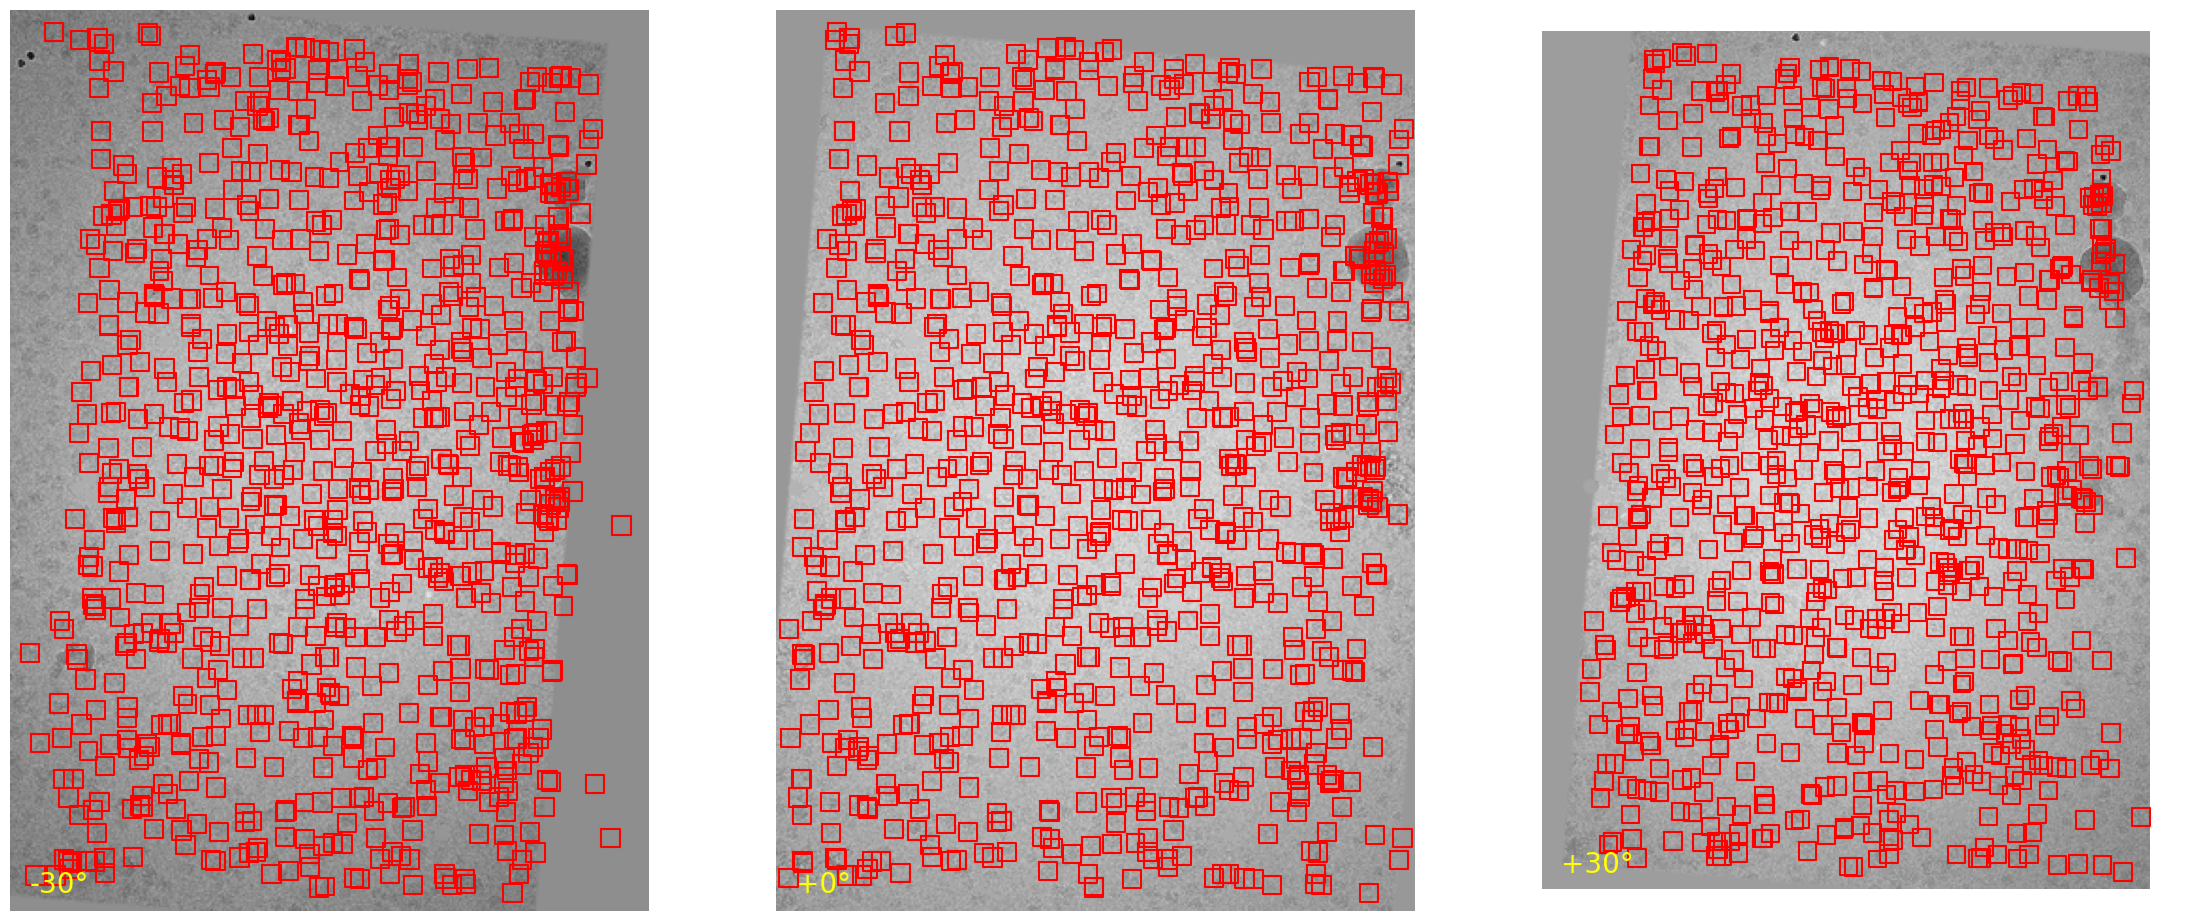

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(28, 12))
for ax_idx, channel_idx in enumerate([10, 20, 30]):
    theta = thetas[channel_idx]

    image = tiltseries[channel_idx]
    image = image.astype(np.uint8)
    h, w = image.shape
    rotated_xyz_indices = inference.rotate_coordinate(xyz_indices=estimated_centers, theta=theta, W=nx, D=nz)
    rotated_bboxes = inference.xyz_to_xy_bbox(rotated_xyz_indices, estimated_diameters)

    axs[ax_idx].imshow(image, cmap='gray')
    for bbox in rotated_bboxes:
        x1, y1, x2, y2 = bbox
        if x1 < 0 or x2 >= w or y1 < 0 or y2 >= h:
            continue
        xs = [x1, x1, x2, x2, x1]
        ys = [y1, y2, y2, y1, y1]
        axs[ax_idx].plot(xs, ys, color='red')

    axs[ax_idx].text(10, h - 10, f'{theta:+d}°', color='yellow', size=20)
    axs[ax_idx].axis('off')
plt.show()